## Lab 3: Ridge Regression and Gradient Boosting With Many Predictors (JPM)

## Step 1: Set up

In [17]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslab import config
from tslab.data import load_market_data
from tslab.team import build_features_jpm, make_dataset_jpm, FEATURE_GROUPS_JPM, ALL_FEATURES_JPM   # OUR features
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import (compare_models, diebold_mariano, dm_verdict, directional_accuracy,
                           directional_accuracy_test, out_of_sample_r2, rmse, mae,
                           simple_backtest, backtest_summary)
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from tslab.features import check_no_lookahead

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(config.SEED)
print("Target stock:", config.TARGET_TICKER)

Target stock: JPM


## Step 2: The data and the walk-forward folds

In [18]:
frame = load_market_data()                                              # one row per JPM trading day
dataset_all = make_dataset_jpm(frame, horizon=1)                        # includes the last row (no target yet)
latest_row = dataset_all.iloc[[-1]]                                     # kept aside for a real forecast
dataset = dataset_all.dropna(subset=["target_return"])
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

print("Rows in the modelling table:", len(dataset))                     # expect 2789
print("Walk-forward folds         :", len(splits))                      # expect 29
print("First test day:", dataset.index[splits[0][1][0]].date(), "| last test day:", dataset.index[splits[-1][1][-1]].date())

Loaded 2989 trading days of JPM, 2015-01-02 to 2026-11-19, with 8 predictor series.
Rows in the modelling table: 2789
Walk-forward folds         : 29
First test day: 2019-10-08 | last test day: 2026-11-18


## Step 3: The table of predictors

In [19]:
pd.Series({g: len(cols) for g, cols in FEATURE_GROUPS_JPM.items()}, name="features").to_frame()

,features
returns,9
volatility,6
technical,9
volume,1
other_markets,15
calendar,7
sector_fin,3


## Step 4: Look-ahead bias

In [20]:
assert check_no_lookahead(frame, build_features_jpm, n_checks=8)
print("PASSED: none of our features changes when the future is removed.")

def features_with_a_leak(market, centred=True):
    table = build_features_jpm(market)
    table["average_gap"] = np.log(market["Close"].rolling(5, center=centred).mean() / market["Close"])
    return table

for centred in (True, False):
    try:
        check_no_lookahead(frame, feature_function=lambda m, c=centred: features_with_a_leak(m, c), n_checks=8)
        print(f"center={centred}: test PASSED (no future data used)")
    except AssertionError as problem:
        print(f"center={centred}: test CAUGHT a leak ->", str(problem)[:150])

PASSED: none of our features changes when the future is removed.
center=True: test CAUGHT a leak -> Look-ahead bias detected on 2025-03-05: these features changed when the future was removed: ['average_gap']
center=False: test PASSED (no future data used)


The look-ahead test confirmed that none of our 50 predictors, including the three new financial-sector features, uses information from the future. When we deliberately added a centred 5-day average, which secretly includes the next two days' prices, the test caught the leak immediately, and with `center=False` (past days only) it passed. The leak also changes the results: the honest model had an R² of about −0.06, slightly worse than the naive forecast, while the leaky feature pushed it to about 0.78 because it was effectively peeking at tomorrow's price. This shows that our results can be trusted, and that a result that looks too good in stock forecasting usually points to a leak, not real skill.

In [21]:
y_all = dataset["target_return"]
X_honest = dataset[ALL_FEATURES_JPM]

def holdout_r2(X):
    X = X.dropna()
    yy = y_all.loc[X.index]
    cut = int(len(X) * 0.7)
    scaler = StandardScaler().fit(X.iloc[:cut])                 # scaler fitted on the training part only
    model = Ridge(alpha=10).fit(scaler.transform(X.iloc[:cut]), yy.iloc[:cut])
    return out_of_sample_r2(yy.iloc[cut:], model.predict(scaler.transform(X.iloc[cut:])))

leak_rows = {"Honest features only": holdout_r2(X_honest)}
for centred in (True, False):
    extra = features_with_a_leak(frame, centred)[["average_gap"]].reindex(dataset.index)
    leak_rows[f"+ 5-day average, center={centred}"] = holdout_r2(pd.concat([X_honest, extra], axis=1))
pd.Series(leak_rows, name="Out-of-sample R2 (holdout)").to_frame().round(4)

,Out-of-sample R2 (holdout)
Honest features only,-0.0571
"+ 5-day average, center=True",0.7798
"+ 5-day average, center=False",-0.0571


## Step 5: Walk-forward folds

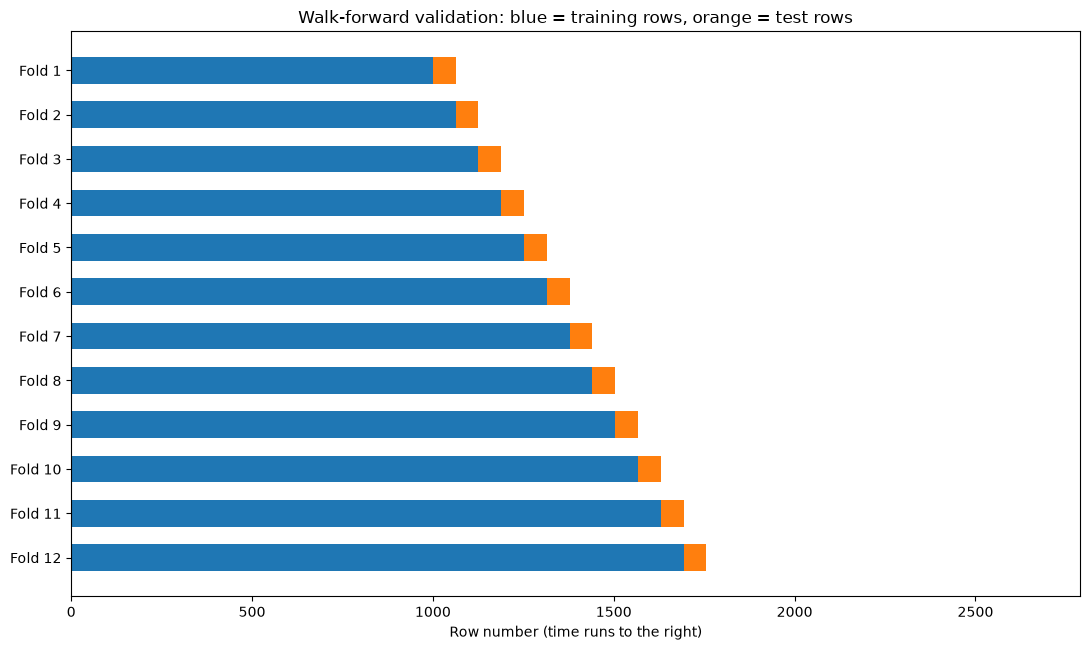

,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
1,1000,2015-10-16,2019-10-07,63,2019-10-08,2020-01-07
2,1063,2015-10-16,2020-01-07,63,2020-01-08,2020-04-07
3,1126,2015-10-16,2020-04-07,63,2020-04-08,2020-07-08


In [22]:
X, y = dataset[ALL_FEATURES_JPM], dataset["target_return"]
plot_walk_forward_layout(splits, len(dataset))
describe_splits(splits, dataset.index).head(3)

**Why this test is honest.** The picture shows the first 12 of our 29 folds, with blue for training days and orange for test days. In every fold the model is trained only on days before the test block and then forecasts the next 63 trading days. Fold 1, for example, trains on 1,000 days (16 October 2015 to 7 October 2019) and tests on 8 October 2019 to 7 January 2020. After each fold the test days join the training data, so the window grows, and a new `StandardScaler` and a new model are fitted on the training rows only. The test days never influence the scaler or the model, and time is never shuffled, so each forecast uses only the past, as it would in real life.

## Step 6: Tune without touching the test period.

In [23]:
tuning_X, tuning_y = X.iloc[: config.INITIAL_TRAIN], y.iloc[: config.INITIAL_TRAIN]   # first 1,000 rows ONLY
inner_splits = list(walk_forward_splits(len(tuning_X), initial_train=500, test_size=100))
print("Tuning folds:", len(inner_splits), "| last tuning day:", tuning_X.index[-1].date(),
      "| first test day:", dataset.index[splits[0][1][0]].date())

def tuning_score(model_factory):
    """Mean squared error of walk-forward predictions INSIDE the tuning block (lower is better)."""
    predicted = walk_forward_predict(model_factory, tuning_X, tuning_y, inner_splits)
    mask = predicted.notna()
    return float(np.mean((tuning_y[mask] - predicted[mask]) ** 2))

# Ridge: grid extended to 1e7 so that the chosen alpha is not on the edge of the grid
alpha_grid = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]
ridge_results = {a: tuning_score(lambda a=a: Ridge(alpha=a)) for a in alpha_grid}
best_alpha = min(ridge_results, key=ridge_results.get)
display(pd.Series(ridge_results, name="Tuning MSE").to_frame().T)
print("Chosen Ridge alpha:", best_alpha)

Tuning folds: 5 | last tuning day: 2019-10-07 | first test day: 2019-10-08


,1,10,100,1000,10000,100000,1000000,10000000
Tuning MSE,0.000193,0.000188,0.000177,0.00017,0.000169,0.000169,0.000169,0.000169


Chosen Ridge alpha: 100000


In [24]:
def make_boosting(max_depth=3, learning_rate=0.03, max_iter=200, loss="squared_error", quantile=None):
    return HistGradientBoostingRegressor(
        loss=loss, quantile=quantile, max_depth=max_depth, learning_rate=learning_rate, max_iter=max_iter,
        min_samples_leaf=40, l2_regularization=1.0, random_state=config.SEED)

grid = [(depth, rate) for depth in (2, 3, 5) for rate in (0.01, 0.03)]
started = time.time()
boost_results = {c: tuning_score(lambda c=c: make_boosting(max_depth=c[0], learning_rate=c[1])) for c in grid}
print(f"Tuning took {time.time() - started:.0f} seconds")
display(pd.Series(boost_results, name="Tuning MSE").rename_axis(["max_depth", "learning_rate"]).to_frame().round(8))
best_depth, best_rate = min(boost_results, key=boost_results.get)
print("Chosen boosting settings: max_depth =", best_depth, ", learning_rate =", best_rate)

Tuning took 8 seconds


Tuning MSE
max_depth learning_rate            
2         0.01             0.000171
          0.03             0.000174
3         0.01             0.000173
          0.03             0.000177
5         0.01             0.000174
          0.03             0.000180

Chosen boosting settings: max_depth = 2 , learning_rate = 0.01


 We tuned both models on the first 1,000 rows only, using 5 small walk-forward folds that end on 7 October 2019, so the test period was never touched. For Ridge, the tuning error fell as the penalty grew and then stopped improving from alpha = 10,000 upward. It chose alpha = 100,000, which is no longer on the edge of the grid now that the grid runs to 10,000,000. A penalty this large shrinks almost every coefficient to zero, so Ridge predicts roughly the same small average return every day: our 50 predictors carry almost no useful signal for JPM's next-day return. For gradient boosting, all six settings scored within a very small range (0.000171 to 0.000180), and the most cautious one won (max_depth = 2, learning_rate = 0.01). That shows tuning cannot create skill when the signal is this weak.

## Step 7: Walk-forward test: the main results table

In [25]:
predictions = {}
started = time.time()
predictions["Ridge"] = walk_forward_predict(lambda: Ridge(alpha=best_alpha), X, y, splits)
predictions["Gradient boosting"] = walk_forward_predict(
    lambda: make_boosting(max_depth=best_depth, learning_rate=best_rate), X, y, splits)
print(f"Walk-forward finished in {time.time() - started:.0f} seconds")

scores = compare_models(dataset, predictions)          # adds the naive row automatically
scores.round(4)

Walk-forward finished in 6 seconds


,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),2.9737,2.0128,1.2504,NaN,0.0000
Ridge,2.9725,2.0066,1.2484,0.5355,0.0005
Gradient boosting,2.9958,2.0223,1.2591,0.5266,-0.0180


In [26]:
scored_rows = pd.concat(predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]
rows = []
for name, series in predictions.items():
    statistic, p_dm = diebold_mariano(actual, series.loc[scored_rows], np.zeros(len(scored_rows)))
    hit_rate, p_dir = directional_accuracy_test(actual, series.loc[scored_rows])
    rows.append({"Model": name, "DM statistic vs naive": statistic, "DM p-value": p_dm,
                 "Verdict": dm_verdict(statistic, p_dm), "Hit rate": hit_rate, "Hit rate p-value (vs 50%)": p_dir,
                 "Share of days predicted UP": (series.loc[scored_rows] > 0).mean()})
dm_table = pd.DataFrame(rows).set_index("Model")
print(f"Share of test days on which JPM actually rose: {(actual > 0).mean():.1%}")
dm_table.round(4)

Share of test days on which JPM actually rose: 53.4%


,DM statistic vs naive,DM p-value,Verdict,Hit rate,Hit rate p-value (vs 50%),Share of days predicted UP
Model,,,,,,
Ridge,-0.2353,0.8140,No significant difference,0.5355,0.0029,0.9911
Gradient boosting,1.7619,0.0783,No significant difference,0.5266,0.0262,0.8547


**No model beats the naive forecast.** Over 1,789 test days (8 October 2019 to 18 November 2026), Ridge's price error (RMSE) was $2.9725 against $2.9737 for "no change", an improvement of about a tenth of a cent. Its out-of-sample R² is only 0.0005. The Diebold-Mariano test gives p = 0.81, so the difference is far from significant. Gradient boosting did slightly worse than naive (RMSE $2.9958, R² −0.018), and that difference is not significant either (p = 0.08). **The direction trap:** Ridge's 53.6% hit rate looks significant (p = 0.003), but Ridge predicted "up" on 99% of days, and JPM rose on 53.4% of test days. A model that always says "up" scores about the same, so the hit rate reflects JPM's upward drift, not forecasting skill. The same applies to gradient boosting, which predicted "up" on 85% of days.

In [ ]:
classical = pd.read_csv(config.OUTPUT_DIR / "predictions_classical.csv", index_col=0, parse_dates=True)
classical = classical.reindex(dataset.index)
combined = {name: classical[name] for name in ["ARIMA", "ARMAX"] if name in classical}
combined.update(predictions)
combined_scores = compare_models(dataset, combined)

common = pd.concat(combined, axis=1).dropna().index
act = dataset.loc[common, "target_return"]
dm_rows = {}
for name, series in combined.items():
    s, p = diebold_mariano(act, series.loc[common], np.zeros(len(common)))
    dm_rows[name] = {"DM statistic vs naive": s, "DM p-value": p, "Verdict": dm_verdict(s, p)}
print("Rows scored:", len(common))
display(combined_scores.round(4))
pd.DataFrame(dm_rows).T

Rows scored: 1789


,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),2.9737,2.0128,1.2504,NaN,0.0000
ARIMA,2.9737,2.0128,1.2504,NaN,0.0000
ARMAX,3.0005,2.0294,1.2635,0.5271,-0.0145
Ridge,2.9725,2.0066,1.2484,0.5355,0.0005
Gradient boosting,2.9958,2.0223,1.2591,0.5266,-0.0180


,DM statistic vs naive,DM p-value,Verdict
ARIMA,1.211325,0.225931,No significant difference
ARMAX,1.035839,0.300418,No significant difference
Ridge,-0.235278,0.81402,No significant difference
Gradient boosting,1.7619,0.078257,No significant difference


## Step 8: Feature group ablation

In [27]:
def score_features(feature_list, model_factory=lambda: Ridge(alpha=best_alpha)):
    predicted = walk_forward_predict(model_factory, dataset[feature_list], y, splits)
    mask = predicted.notna()
    return out_of_sample_r2(y[mask], predicted[mask])

all_features_r2 = score_features(ALL_FEATURES_JPM)
rows = []
for group, names in FEATURE_GROUPS_JPM.items():
    others = [f for f in ALL_FEATURES_JPM if f not in names]
    rows.append({"Group": group, "Features": len(names),
                 "R2 using ONLY this group": score_features(names),
                 "R2 WITHOUT this group": score_features(others)})

tech = [f for f in ALL_FEATURES_JPM if f.startswith("TECH_")]
rows.append({"Group": "TECH only (inside other_markets)", "Features": len(tech),
             "R2 using ONLY this group": score_features(tech),
             "R2 WITHOUT this group": score_features([f for f in ALL_FEATURES_JPM if f not in tech])})

ablation = pd.DataFrame(rows).set_index("Group")
ablation["Change vs all features"] = ablation["R2 WITHOUT this group"] - all_features_r2
print(f"R2 with ALL features (Ridge): {all_features_r2:.5f}")
ablation.round(5)

R2 with ALL features (Ridge): 0.00051


,Features,R2 using ONLY this group,R2 WITHOUT this group,Change vs all features
Group,,,,
returns,9,0.00090,0.00035,-0.00016
volatility,6,0.00056,0.00065,0.00013
technical,9,0.00075,0.00050,-0.00001
volume,1,0.00070,0.00051,-0.00000
other_markets,15,0.00046,0.00078,0.00027
calendar,7,0.00069,0.00052,0.00000
sector_fin,3,0.00072,0.00053,0.00002
TECH only (inside other_markets),2,0.00066,0.00057,0.00006


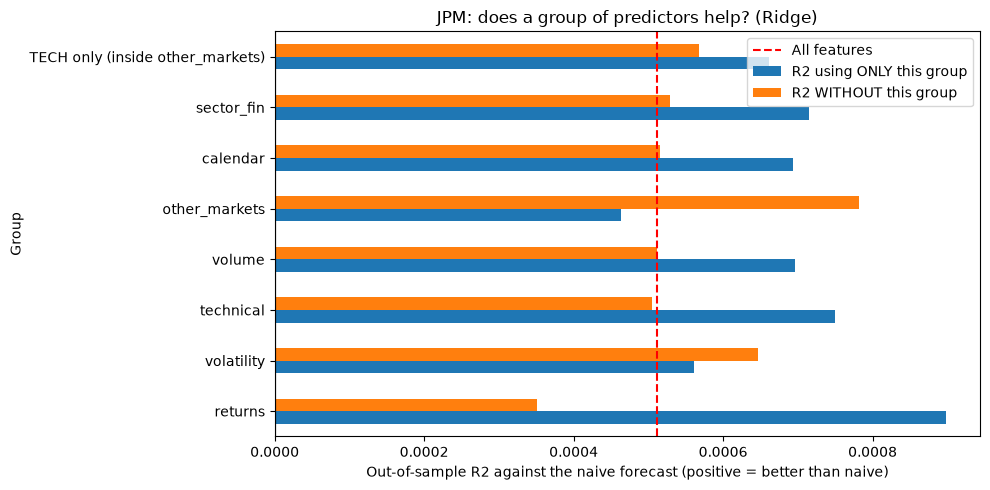

In [28]:
ablation[["R2 using ONLY this group", "R2 WITHOUT this group"]].plot.barh(figsize=(10, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(all_features_r2, color="red", linestyle="--", label="All features")
plt.xlabel("Out-of-sample R2 against the naive forecast (positive = better than naive)")
plt.title("JPM: does a group of predictors help? (Ridge)")
plt.legend(); plt.tight_layout(); plt.show()

No group of predictors has a measurable effect. With all 50 features, Ridge's out-of-sample R² is only 0.0005, and removing any one group changes it by at most 0.0003. The brief says a difference that small (well below 0.001) is not a finding. Removing the past-returns group lowers R² the most (by 0.00016), and removing the other-markets or volatility groups slightly raises it (by 0.00027 and 0.00013), but all of these are noise-sized. Every group used on its own also scores between 0.0005 and 0.0009, which is practically the same as naive. Our new financial-sector group (sector_fin) does not help more than the technology fund: removing it changes R² by 0.00002, and removing TECH changes it by 0.00006. JPM's next-day return is essentially unpredictable from any of these predictors, which is why Ridge chose such a large penalty and why no model beats the naive forecast.

## Step 9: Permutation importance

Importance measured on 2024-11-14 to 2026-11-18


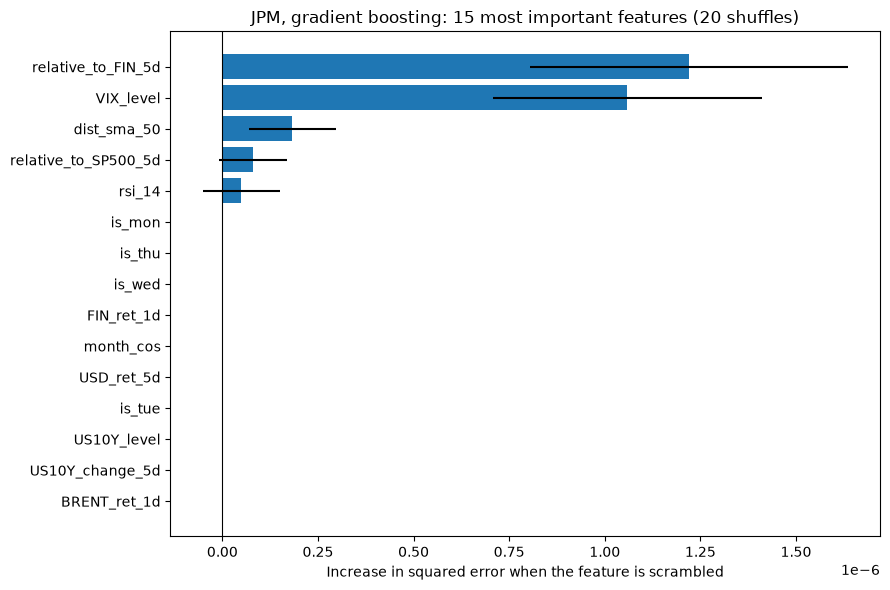

In [29]:
hold = 504
X_fit, y_fit = X.iloc[:-hold], y.iloc[:-hold]
X_hold, y_hold = X.iloc[-hold:], y.iloc[-hold:]
print("Importance measured on", X_hold.index[0].date(), "to", X_hold.index[-1].date())

model = make_boosting(max_depth=best_depth, learning_rate=best_rate).fit(X_fit, y_fit)
result = permutation_importance(model, X_hold, y_hold, scoring="neg_mean_squared_error",
                                n_repeats=20, random_state=config.SEED)
importance = pd.Series(result.importances_mean, index=ALL_FEATURES_JPM).sort_values()
spread = pd.Series(result.importances_std, index=ALL_FEATURES_JPM)[importance.index]

top = importance.tail(15)
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, xerr=spread[top.index].values, color="tab:blue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Increase in squared error when the feature is scrambled")
plt.title("JPM, gradient boosting: 15 most important features (20 shuffles)")
plt.tight_layout(); plt.show()

Gradient boosting relied mainly on two features: relative_to_FIN_5d, our new financial-sector feature, and VIX_level, a measure of market fear. dist_sma_50 had a small effect, while the error bars for relative_to_SP500_5d and rsi_14 cross zero, so their importance cannot be told apart from zero. All the other features, including calendar, oil, dollar and interest rates, had no importance, because the cautious model used only a few features. The increases in error are tiny and were measured on one two-year window (November 2024 to November 2026), so they may not hold in other periods. Importance also does not mean skill: the same model did not beat the naive forecast, and removing the sector_fin group in Step 8 made no measurable difference.

## Step 10: Forecast for the next trading day

In [30]:
final_scaler = StandardScaler().fit(X)               # all rows with a known target; nothing from the future
Xs = final_scaler.transform(X)
final_ridge = Ridge(alpha=best_alpha).fit(Xs, y)
final_boost = make_boosting(max_depth=best_depth, learning_rate=best_rate).fit(Xs, y)
final_q10 = make_boosting(loss="quantile", quantile=0.10).fit(Xs, y)
final_q90 = make_boosting(loss="quantile", quantile=0.90).fit(Xs, y)

today = final_scaler.transform(latest_row[ALL_FEATURES_JPM])
last_close = float(latest_row["close"].iloc[0])
next_date = latest_row.index[0] + pd.offsets.BDay(1)
forecast = pd.Series({
    "Last close": last_close,
    "Ridge forecast": last_close * float(np.exp(final_ridge.predict(today))[0]),
    "Gradient boosting forecast": last_close * float(np.exp(final_boost.predict(today))[0]),
    "10% quantile": last_close * float(np.exp(final_q10.predict(today))[0]),
    "90% quantile": last_close * float(np.exp(final_q90.predict(today))[0]),
})
print(f"Data up to {latest_row.index[0].date()}; forecast for {next_date.date()}")
forecast.round(2)

Data up to 2026-11-19; forecast for 2026-11-20


Last close                    320.22
Ridge forecast                320.58
Gradient boosting forecast    320.56
10% quantile                  312.83
90% quantile                  327.47
dtype: float64

Using data up to 19 November 2026, both models forecast JPM’s close for 20 November 2026 at about $320.6 (Ridge $320.58, gradient boosting $320.56), almost the same as the last close of $320.22. The 10% to 90% range runs from $312.83 to $327.47, a spread of about $14.60, which is about 40 times bigger than the $0.36 gap between the forecast and the last close.

## Save

In [16]:
os.makedirs(config.OUTPUT_DIR, exist_ok=True)
pd.concat(predictions, axis=1).to_csv(config.OUTPUT_DIR / "predictions_ml.csv")      # columns: Ridge, Gradient boosting
with open(config.OUTPUT_DIR / "ml_best_params.json", "w") as f:
    json.dump({"best_alpha": float(best_alpha), "best_depth": int(best_depth), "best_rate": float(best_rate)}, f, indent=2)
print("Saved outputs/predictions_ml.csv and outputs/ml_best_params.json")

Saved outputs/predictions_ml.csv and outputs/ml_best_params.json


## Conclusion


We tested whether Ridge regression and gradient boosting, using 50 predictors including our new financial-sector group, could forecast JPM's next-day return better than the naive forecast ("tomorrow = today"). Every model was tested walk-forward on 1,789 unseen trading days (October 2019 to November 2026), with settings chosen only from earlier data and no future information in any predictor. Neither model beat naive: Ridge's error was $2.9725 against $2.9737 for naive (DM p = 0.81), and gradient boosting was slightly worse ($2.9958, p = 0.08). Ridge's 53.6% directional accuracy only reflects JPM's upward drift, because it predicted "up" on 99% of days while JPM rose on 53.4% of them.

The other results support this finding. Ridge chose a very large penalty that switches almost every predictor off, the ablation showed no measurable effect from any group of predictors, and permutation importance found only small effects on one window. Tomorrow's forecast ($320.58 against a last close of $320.22) is essentially "no change", with a wide range of $312.83 to $327.47. Our honest conclusion is that these predictors cannot forecast JPM's next-day price better than "no change", so a portfolio manager should rely on the range rather than the point forecast.